# 04 — Exact fault-type diagnosis

This notebook presents the saved pooled multiclass diagnosis results. It does not retrain a model. Binary detection and fault-type diagnosis are separate tasks: first the system asks whether operation is normal or faulty; diagnosis then predicts the original fault label for fault-labelled rows.

The evidence uses the quality-controlled cleaned table, the saved Phase 5 feature table, and the duplicate-excluded split assignments. Building-specific diagnosis is not presented as a separate headline model because several fault labels have insufficient within-building support.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'normal': '#457b9d', 'fault': '#e76f51', 'accent': '#2a9d8f', 'dark': '#264653'}

def find_root():
    for candidate in [Path.cwd(), Path.cwd().parent, Path('/Users/mili/Desktop/IRPN')]:
        if (candidate / 'pyproject.toml').exists() and (candidate / 'results').exists():
            return candidate
    raise FileNotFoundError('Open this notebook from the IRPN repository or set ROOT manually.')

ROOT = find_root()

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

def require(*paths):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError('Missing saved artefacts. Run the pipeline commands first:\n' + '\n'.join(missing))

def pct(value):
    return f'{100 * value:.1f}%' if pd.notna(value) else 'n/a'

## 1. Load and describe the diagnosis artefacts

In [2]:
RESULTS = ROOT / 'results' / 'diagnosis'
SENSITIVITY_RESULTS = ROOT / 'results' / 'diagnosis_symptom_only'
DATA = ROOT / 'data' / 'interim' / 'cleaned' / 'cleaned_ahu.csv'
FEATURES = ROOT / 'data' / 'interim' / 'features' / 'multibuilding_features.csv'
require(RESULTS / 'diagnosis_manifest.json', RESULTS / 'diagnosis_metrics_summary.csv', RESULTS / 'diagnosis_metrics_by_class.csv', RESULTS / 'diagnosis_metrics_by_building.csv', RESULTS / 'diagnosis_confusion_matrix.csv', RESULTS / 'diagnosis_support_by_split.csv', SENSITIVITY_RESULTS / 'diagnosis_manifest.json', SENSITIVITY_RESULTS / 'diagnosis_metrics_summary.csv', SENSITIVITY_RESULTS / 'diagnosis_metrics_by_class.csv', DATA, FEATURES)
manifest = read_json(RESULTS / 'diagnosis_manifest.json')
sensitivity_manifest = read_json(SENSITIVITY_RESULTS / 'diagnosis_manifest.json')
summary = pd.read_csv(RESULTS / 'diagnosis_metrics_summary.csv').drop(columns=['variant'], errors='ignore')
by_class = pd.read_csv(RESULTS / 'diagnosis_metrics_by_class.csv').drop(columns=['variant'], errors='ignore')
confusion = pd.read_csv(RESULTS / 'diagnosis_confusion_matrix.csv')
by_building = pd.read_csv(RESULTS / 'diagnosis_metrics_by_building.csv').drop(columns=['variant'], errors='ignore')
sensitivity_summary = pd.read_csv(SENSITIVITY_RESULTS / 'diagnosis_metrics_summary.csv').drop(columns=['variant'], errors='ignore')
sensitivity_by_class = pd.read_csv(SENSITIVITY_RESULTS / 'diagnosis_metrics_by_class.csv').drop(columns=['variant'], errors='ignore')
print('Rows used:', f"{manifest['row_count']:,}")
print('Duplicate policy:', manifest.get('duplicate_policy', 'not recorded'))
print('Saved feature set: default engineered features')
print('Predictor count:', manifest.get('feature_counts', {}).get('physical_signal', 'not recorded'))
print('Minimum fault rows:', manifest.get('minimum_fault_rows'))
print('Model-score threshold:', manifest.get('model_score_threshold'))
display(summary.round(3))

Rows used: 354,587
Duplicate policy: exclude_ambiguous_keys
Saved feature set: default engineered features
Predictor count: 88
Minimum fault rows: 30
Model-score threshold: 0.7


,design,fold,task,evaluated_rows,unsupported_rows,all_test_rows,class_count,model_score_threshold,coverage,above_threshold_rows,abstained_rows,abstention_rate,above_threshold_accuracy,accuracy,balanced_accuracy,macro_f1,weighted_f1,minimum_fault_rows,excluded_fault_rows
0,building_held_out,fold_001,fault_type,8974,44182,53156,4,0.7,0.999,8963,11,0.001,0.998,0.998,0.996,0.992,0.998,30,1
1,building_held_out,fold_002,fault_type,12188,0,12188,4,0.7,0.990,12061,127,0.010,0.434,0.436,0.731,0.367,0.414,30,1
2,building_held_out,fold_003,fault_type,56130,0,56130,4,0.7,0.977,54856,1274,0.023,0.736,0.725,0.521,0.345,0.768,30,1
3,chronological,fold_001,fault_type,20948,0,20948,6,0.7,0.995,20851,97,0.005,0.991,0.989,0.979,0.870,0.992,30,1
4,nested_grouped,fold_001,fault_type,32404,0,32404,6,0.7,0.939,30413,1991,0.061,0.828,0.791,0.755,0.733,0.782,30,1
5,nested_grouped,fold_002,fault_type,19710,0,19710,6,0.7,0.996,19640,70,0.004,0.985,0.983,0.867,0.878,0.983,30,1
6,nested_grouped,fold_003,fault_type,24433,0,24433,6,0.7,0.999,24397,36,0.001,1.000,1.000,0.993,0.993,1.000,30,1
7,nested_grouped,fold_004,fault_type,22616,0,22616,6,0.7,1.000,22612,4,0.000,1.000,1.000,0.999,0.996,1.000,30,1
8,nested_grouped,fold_005,fault_type,22311,0,22311,6,0.7,0.999,22296,15,0.001,1.000,1.000,0.997,0.996,1.000,30,1


## 2. Why the diagnosis result is pooled

            Fault-type diagnosis is reported as a pooled experiment because several fault labels are absent or very rare within individual buildings. Training a separate classifier for a building that has almost no examples of a fault would produce an unsupported or misleading result. The table below shows the available class support before any model is fitted.

In [3]:
data = pd.read_csv(DATA, usecols=['building', 'label'], low_memory=False)
fault_support = data[~data['label'].astype('string').str.contains('Normal', case=False, na=False)]
fault_support = fault_support.groupby(['building', 'label']).size().rename('rows').reset_index()
display(fault_support.pivot(index='label', columns='building', values='rows').fillna(0).astype(int))

building,auditorium,hospital,office
label,,,
Cooling pump fault,19292,0,0
Cooling supply temperature fault,0,1,0
Heating pump fault,24890,0,0
Return air temperature fault,1734,8756,6999
Supply air temperature fault,404,9,1031
Supply fan fault,6525,1921,47983
Valve position fault,311,1502,117


## 3. Overall diagnosis performance

In [4]:
overall = summary.groupby(['design', 'task'], as_index=False).agg(
    evaluated_rows=('evaluated_rows', 'sum'), unsupported_rows=('unsupported_rows', 'sum'),
    above_threshold_rows=('above_threshold_rows', 'sum'), abstained_rows=('abstained_rows', 'sum'),
    mean_fold_coverage=('coverage', 'mean'), macro_f1=('macro_f1', 'mean'), weighted_f1=('weighted_f1', 'mean'),
    above_threshold_accuracy=('above_threshold_accuracy', 'mean')
)
overall['row_weighted_coverage'] = overall['above_threshold_rows'] / overall['evaluated_rows'].where(overall['evaluated_rows'].gt(0))
display(overall.round(3))

,design,task,evaluated_rows,unsupported_rows,above_threshold_rows,abstained_rows,mean_fold_coverage,macro_f1,weighted_f1,above_threshold_accuracy,row_weighted_coverage
0,building_held_out,fault_type,77292,44182,75880,1412,0.989,0.568,0.726,0.723,0.982
1,chronological,fault_type,20948,0,20851,97,0.995,0.870,0.992,0.991,0.995
2,nested_grouped,fault_type,121474,0,119358,2116,0.987,0.919,0.953,0.962,0.983


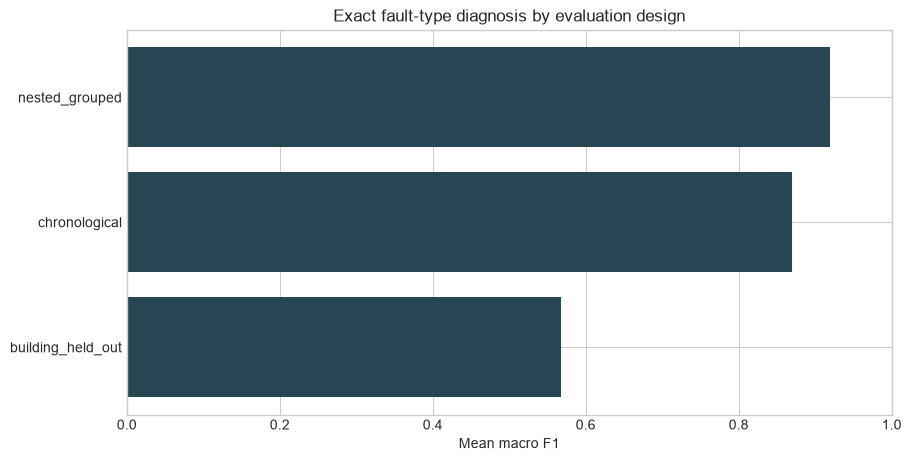

In [5]:
plot_data = overall[overall['task'].eq('fault_type')].sort_values('macro_f1')
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.barh(plot_data['design'], plot_data['macro_f1'], color=COLORS['dark'])
ax.set_xlim(0, 1)
ax.set_xlabel('Mean macro F1')
ax.set_title('Exact fault-type diagnosis by evaluation design')
plt.show()

Macro F1 gives each retained fault type equal importance. Weighted F1 reflects the row distribution and can be higher when common fault types are easier. `unsupported_rows` are reported separately when a class appears in evaluation but was absent from the training fold; they are not silently treated as ordinary model errors.

## 4. Fault-type performance

In [6]:
fault_classes = by_class[by_class['task'].eq('fault_type')].copy()
class_summary = fault_classes.groupby('class_label', as_index=False).agg(
    mean_f1=('f1', 'mean'), mean_precision=('precision', 'mean'), mean_recall=('recall', 'mean'), support=('support', 'sum')
).sort_values('mean_f1')
display(class_summary.round(3))

,class_label,mean_f1,mean_precision,mean_recall,support
5,Valve position fault,0.590,0.556,0.750,3896
3,Supply air temperature fault,0.759,0.758,0.853,3039
2,Return air temperature fault,0.816,0.899,0.822,37510
4,Supply fan fault,0.904,0.892,0.968,122945
1,Heating pump fault,0.999,0.999,0.999,32416
0,Cooling pump fault,0.999,0.999,1.000,19908


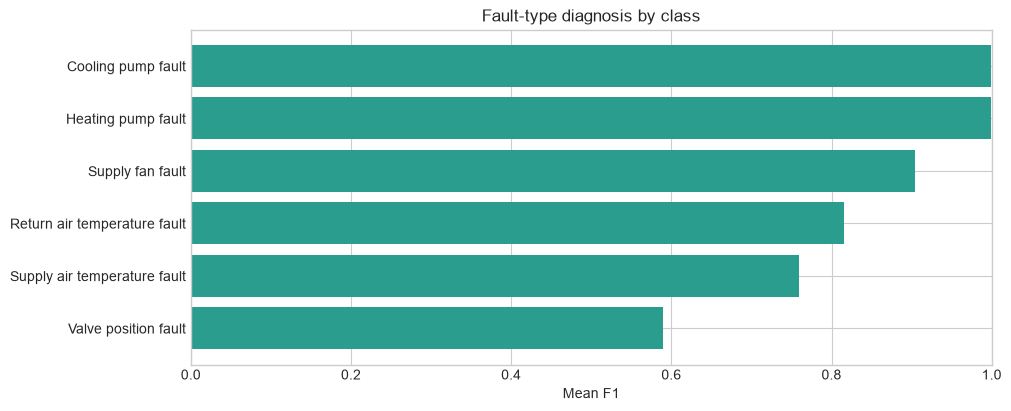

In [7]:
fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(class_summary))), constrained_layout=True)
ax.barh(class_summary['class_label'], class_summary['mean_f1'], color=COLORS['accent'])
ax.set_xlim(0, 1)
ax.set_xlabel('Mean F1')
ax.set_title('Fault-type diagnosis by class')
plt.show()

## 5. Sensitivity check: symptoms-only diagnosis

The practical diagnosis uses the approved BMS measurements, including equipment-state signals that a real building-management system would normally expose. This sensitivity run repeats the same rows, folds, XGBoost settings and 70% abstention rule while removing direct fan, valve, exchanger and pump-status channels. It asks whether exact diagnosis remains strong when the model must rely more on measured consequences such as temperatures and airflow. It is a robustness check, not a replacement headline model.

,design,task,practical_macro_f1,practical_weighted_f1,practical_coverage,evaluated_rows_x,symptoms_only_macro_f1,symptoms_only_weighted_f1,symptoms_only_coverage,evaluated_rows_y
0,building_held_out,fault_type,0.568,0.726,0.989,77292,0.345,0.614,0.682,77292
1,chronological,fault_type,0.870,0.992,0.995,20948,0.684,0.947,0.935,20948
2,nested_grouped,fault_type,0.919,0.953,0.987,121474,0.785,0.905,0.895,121474


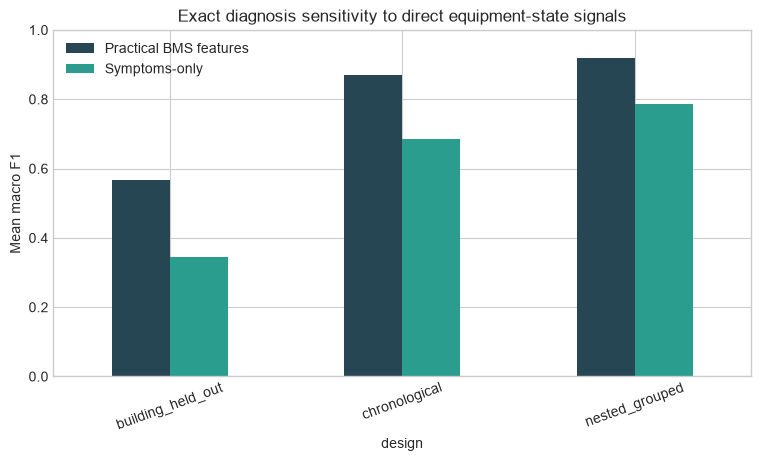

In [8]:
def aggregate_diagnosis(frame):
    return frame.groupby(['design', 'task'], as_index=False).agg(
        mean_macro_f1=('macro_f1', 'mean'),
        mean_weighted_f1=('weighted_f1', 'mean'),
        mean_coverage=('coverage', 'mean'),
        evaluated_rows=('evaluated_rows', 'sum'),
    )

headline_comparison = aggregate_diagnosis(summary).rename(columns={
    'mean_macro_f1': 'practical_macro_f1', 'mean_weighted_f1': 'practical_weighted_f1', 'mean_coverage': 'practical_coverage'
})
symptom_comparison = aggregate_diagnosis(sensitivity_summary).rename(columns={
    'mean_macro_f1': 'symptoms_only_macro_f1', 'mean_weighted_f1': 'symptoms_only_weighted_f1', 'mean_coverage': 'symptoms_only_coverage'
})
sensitivity_comparison = headline_comparison.merge(symptom_comparison, on=['design', 'task'], how='outer')
display(sensitivity_comparison.round(3))
plot_frame = sensitivity_comparison[sensitivity_comparison['task'].eq('fault_type')].set_index('design')[['practical_macro_f1', 'symptoms_only_macro_f1']]
plot_frame.columns = ['Practical BMS features', 'Symptoms-only']
plot_frame.plot.bar(figsize=(9, 4.5), color=[COLORS['dark'], COLORS['accent']])
plt.ylim(0, 1)
plt.ylabel('Mean macro F1')
plt.title('Exact diagnosis sensitivity to direct equipment-state signals')
plt.xticks(rotation=20)
plt.show()

In [9]:
def class_average(frame):
    return frame.groupby('class_label', as_index=False).agg(
        f1=('f1', 'mean'), recall=('recall', 'mean'), support=('support', 'sum')
    )

class_comparison = class_average(fault_classes).rename(columns={'f1': 'practical_f1', 'recall': 'practical_recall'})
symptom_class_comparison = class_average(sensitivity_by_class[sensitivity_by_class['task'].eq('fault_type')]).rename(columns={'f1': 'symptoms_only_f1', 'recall': 'symptoms_only_recall'})
class_comparison = class_comparison.merge(symptom_class_comparison, on='class_label', how='outer', suffixes=('', '_symptoms'))
display(class_comparison[['class_label', 'practical_f1', 'symptoms_only_f1', 'practical_recall', 'symptoms_only_recall', 'support']].round(3))

,class_label,practical_f1,symptoms_only_f1,practical_recall,symptoms_only_recall,support
0,Cooling pump fault,0.999,0.966,1.000,0.990,19908
1,Heating pump fault,0.999,0.966,0.999,0.988,32416
2,Return air temperature fault,0.816,0.706,0.822,0.734,37510
3,Supply air temperature fault,0.759,0.424,0.853,0.666,3039
4,Supply fan fault,0.904,0.855,0.968,0.863,122945
5,Valve position fault,0.590,0.260,0.750,0.289,3896


## 6. Diagnosis performance by building

These metrics use the same pooled model and split assignments as the overall table. They show where the pooled classifier is strong or weak without implying that a separate building model was trained.

In [10]:
building_view = by_building[by_building['task'].eq('fault_type')].copy()
display(building_view.sort_values(['design', 'building'])[['design', 'fold', 'building', 'support', 'macro_f1', 'weighted_f1', 'balanced_accuracy']].round(3))
building_summary = building_view.groupby(['design', 'building'], as_index=False).agg(mean_macro_f1=('macro_f1', 'mean'), test_rows=('support', 'sum'))
display(building_summary.round(3))

,design,fold,building,support,macro_f1,weighted_f1,balanced_accuracy
0,building_held_out,fold_001,auditorium,8974,0.992,0.998,0.996
1,building_held_out,fold_002,hospital,12188,0.367,0.414,0.731
2,building_held_out,fold_003,office,56130,0.345,0.768,0.521
3,chronological,fold_001,auditorium,9696,0.983,0.997,0.997
4,chronological,fold_001,hospital,2168,0.318,0.948,0.630
5,chronological,fold_001,office,9084,0.667,1.000,1.000
6,nested_grouped,fold_001,auditorium,10831,0.993,0.999,0.996
9,nested_grouped,fold_002,auditorium,7489,1.000,1.000,1.000
12,nested_grouped,fold_003,auditorium,10981,0.999,1.000,0.997
15,nested_grouped,fold_004,auditorium,11818,0.998,1.000,0.998


,design,building,mean_macro_f1,test_rows
0,building_held_out,auditorium,0.992,8974
1,building_held_out,hospital,0.367,12188
2,building_held_out,office,0.345,56130
3,chronological,auditorium,0.983,9696
4,chronological,hospital,0.318,2168
5,chronological,office,0.667,9084
6,nested_grouped,auditorium,0.997,53156
7,nested_grouped,hospital,0.370,12188
8,nested_grouped,office,0.656,56130


## 7. Confusion matrix

class_label,Valve position fault,Supply air temperature fault,Return air temperature fault,Supply fan fault,Heating pump fault,Cooling pump fault
class_label,,,,,,
Valve position fault,2216,1,1415,263,0,1
Supply air temperature fault,3,1988,728,319,0,1
Return air temperature fault,4063,544,24260,8622,20,1
Supply fan fault,2782,0,10885,109272,2,4
Heating pump fault,0,1,24,6,32385,0
Cooling pump fault,0,5,0,0,0,19903


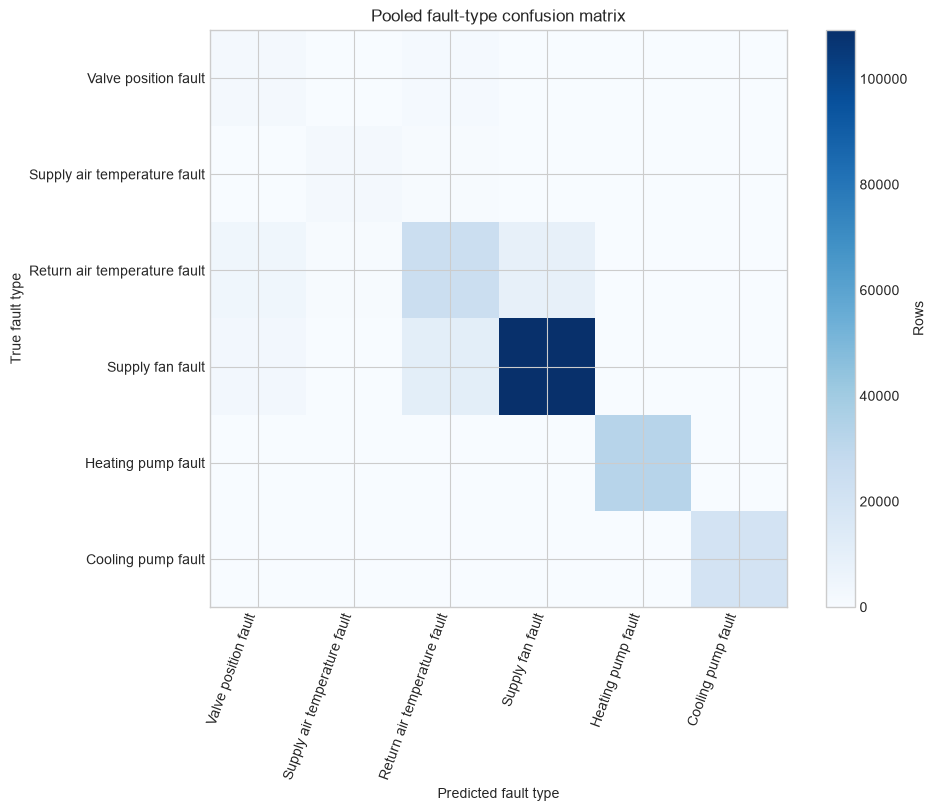

In [11]:
matrix = confusion[confusion['task'].eq('fault_type')].pivot_table(index='true_label', columns='predicted_label', values='count', aggfunc='sum', fill_value=0)
matrix = matrix.reindex(index=class_summary['class_label'], columns=class_summary['class_label'], fill_value=0)
display(matrix)
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
image = ax.imshow(matrix.to_numpy(), cmap='Blues')
ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=70, ha='right')
ax.set_yticks(range(len(matrix.index)), matrix.index)
ax.set_title('Pooled fault-type confusion matrix')
ax.set_xlabel('Predicted fault type')
ax.set_ylabel('True fault type')
fig.colorbar(image, ax=ax, label='Rows')
plt.show()

**Model-score caution.** The saved model score is used for the configured abstention rule; it is not automatically a calibrated probability. A diagnosis shown at the threshold should remain an inspection aid, not an automatic maintenance decision.

## 8. Diagnosis limitations and next evidence

In [12]:
limitations = pd.DataFrame([
    ['Task boundary', 'Diagnosis predicts fault types; it does not replace binary detection.'],
    ['Class support', 'Rare or unsupported classes are reported separately and should not be over-interpreted.'],
    ['Generalisation', 'These are pooled diagnosis outputs; building-specific diagnosis requires a separate class-support check.'],
    ['Model score', 'The threshold provides abstention, not a calibrated probability.'],
], columns=['issue', 'interpretation'])
display(limitations)

,issue,interpretation
0,Task boundary,Diagnosis predicts fault types; it does not re...
1,Class support,Rare or unsupported classes are reported separ...
2,Generalisation,These are pooled diagnosis outputs; building-s...
3,Model score,"The threshold provides abstention, not a calib..."


## 9. Train/test support matrix

The diagnosis outputs already report test support, per-building metrics and unsupported rows. This additional table makes the class-support limitation explicit for every active design, fold, building and eligible fault type. A class with zero training rows cannot be learned in that fold, even if it appears in the test data.

In [13]:
support_path = RESULTS / 'diagnosis_support_by_split.csv'
support_matrix = pd.read_csv(support_path)
display(support_matrix)

unsupported = support_matrix[support_matrix['unsupported_test_rows'].gt(0)]
display(unsupported[['design', 'fold', 'building', 'fault_type', 'train_rows', 'test_rows', 'unsupported_test_rows']])

,design,fold,building,fault_type,train_rows,test_rows,present_in_training,unsupported_test_rows
0,chronological,fold_001,auditorium,Cooling pump fault,10857,616,True,0
1,chronological,fold_001,auditorium,Heating pump fault,17364,7526,True,0
2,chronological,fold_001,auditorium,Return air temperature fault,1083,179,True,0
3,chronological,fold_001,auditorium,Supply air temperature fault,253,49,True,0
4,chronological,fold_001,auditorium,Supply fan fault,5021,1297,True,0
...,...,...,...,...,...,...,...,...
139,nested_grouped,fold_005,office,Heating pump fault,0,0,False,0
140,nested_grouped,fold_005,office,Return air temperature fault,5269,1217,True,0
141,nested_grouped,fold_005,office,Supply air temperature fault,756,245,True,0
142,nested_grouped,fold_005,office,Supply fan fault,33189,8631,True,0


,design,fold,building,fault_type,train_rows,test_rows,unsupported_test_rows
9,chronological,fold_001,hospital,Supply air temperature fault,0,8,8
18,building_held_out,fold_001,auditorium,Cooling pump fault,0,19292,19292
19,building_held_out,fold_001,auditorium,Heating pump fault,0,24890,24890
20,building_held_out,fold_001,auditorium,Return air temperature fault,0,1734,1734
21,building_held_out,fold_001,auditorium,Supply air temperature fault,0,404,404
22,building_held_out,fold_001,auditorium,Supply fan fault,0,6525,6525
23,building_held_out,fold_001,auditorium,Valve position fault,0,311,311
32,building_held_out,fold_002,hospital,Return air temperature fault,0,8756,8756
33,building_held_out,fold_002,hospital,Supply air temperature fault,0,9,9
34,building_held_out,fold_002,hospital,Supply fan fault,0,1921,1921


This is a support report, not a new model run. It explains why some building-held-out fault-type scores are not reliable: pump faults occur in the auditorium but have zero training rows when another building is held out. Such rows are reported as unsupported rather than presented as ordinary classification errors.